In [41]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/OnlineRetail.csv', encoding='latin1')

print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nData Types:")
print(df.dtypes)


Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 Rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Data Types:
InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object


In [42]:
rfm_df = df.copy()

rfm_df['InvoiceDate'] = pd.to_datetime(
    rfm_df['InvoiceDate'], errors='coerce'
)
rfm_df['CustomerID'] = pd.to_numeric(
    rfm_df['CustomerID'], errors='coerce'
)

rfm_df = rfm_df.dropna(
    subset=['CustomerID', 'InvoiceNo', 'InvoiceDate', 'Quantity', 'UnitPrice']
)

rfm_df = rfm_df[
    ~rfm_df['InvoiceNo'].astype(str).str.startswith('C')
]

rfm_df = rfm_df[
    (rfm_df['Quantity'] > 0) &
    (rfm_df['UnitPrice'] > 0)
]

rfm_df['TotalAmount'] = (
    rfm_df['Quantity'] * rfm_df['UnitPrice']
)

rfm_df = rfm_df.drop_duplicates()

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", rfm_df.shape)
print("Unique Customers:", rfm_df['CustomerID'].nunique())
print("Missing Customer IDs:", rfm_df['CustomerID'].isna().sum())
print("Cancelled Invoices Remaining:",
      rfm_df['InvoiceNo'].astype(str).str.startswith('C').sum())
print("Invalid Quantities Remaining:", (rfm_df['Quantity'] <= 0).sum())
print("Invalid Prices Remaining:", (rfm_df['UnitPrice'] <= 0).sum())


Original Dataset Shape: (541909, 8)
Cleaned Dataset Shape: (392692, 9)
Unique Customers: 4338
Missing Customer IDs: 0
Cancelled Invoices Remaining: 0
Invalid Quantities Remaining: 0
Invalid Prices Remaining: 0


In [43]:
snapshot_date = rfm_df['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = rfm_df.groupby('CustomerID').agg(
    Recency=('InvoiceDate', lambda x: (snapshot_date - x.max()).days),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('TotalAmount', 'sum')
).reset_index()

print("Reference Date:", snapshot_date)
print("RFM Table Shape:", rfm.shape)
print("\nRFM Summary:")
display(rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))

print("\nFirst 5 Customers:")
display(rfm.head().round(2))

Reference Date: 2011-12-10 12:50:00
RFM Table Shape: (4338, 4)

RFM Summary:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02



First 5 Customers:


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [44]:
rfm['R_Score'] = pd.qcut(
    rfm['Recency'].rank(method='first'),
    5, labels=[5, 4, 3, 2, 1]
).astype(int)

rfm['F_Score'] = pd.qcut(
    rfm['Frequency'].rank(method='first'),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['M_Score'] = pd.qcut(
    rfm['Monetary'].rank(method='first'),
    5, labels=[1, 2, 3, 4, 5]
).astype(int)

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str) +
    rfm['F_Score'].astype(str) +
    rfm['M_Score'].astype(str)
)

print("RFM Scores Created Successfully")
display(rfm.head(10).round(2))


RFM Scores Created Successfully


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,2,7,4310.00,5,5,5,555
2,12348.0,75,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,310,1,334.40,1,1,2,112
5,12352.0,36,8,2506.04,3,5,5,355
6,12353.0,204,1,89.00,1,1,1,111
7,12354.0,232,1,1079.40,1,1,4,114
8,12355.0,214,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,4,3,5,435


In [45]:
def assign_segment(row):
    r = row['R_Score']
    f = row['F_Score']
    m = row['M_Score']

    if r >= 4 and f >= 4 and m >= 4:
        return 'Champions'
    elif r >= 3 and f >= 4:
        return 'Loyal Customers'
    elif r >= 4 and f <= 2:
        return 'Recent Customers'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r == 1 and f == 1:
        return 'Lost Customers'
    else:
        return 'Potential Loyalists'

rfm['Segment'] = rfm.apply(assign_segment, axis=1)

print("Customer Segment Counts:")
display(
    rfm['Segment'].value_counts()
    .rename_axis('Segment')
    .reset_index(name='Customer Count')
)

print("RFM Table Preview:")
display(rfm.head(10).round(2))


Customer Segment Counts:


,Segment,Customer Count
0,Potential Loyalists,1551
1,Champions,942
2,At Risk,661
3,Loyal Customers,508
4,Lost Customers,366
5,Recent Customers,310


RFM Table Preview:


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346.0,326,1,77183.60,1,1,5,115,Lost Customers
1,12347.0,2,7,4310.00,5,5,5,555,Champions
2,12348.0,75,4,1797.24,2,4,4,244,At Risk
3,12349.0,19,1,1757.55,4,1,4,414,Recent Customers
4,12350.0,310,1,334.40,1,1,2,112,Lost Customers
5,12352.0,36,8,2506.04,3,5,5,355,Loyal Customers
6,12353.0,204,1,89.00,1,1,1,111,Lost Customers
7,12354.0,232,1,1079.40,1,1,4,114,Lost Customers
8,12355.0,214,1,459.40,1,1,2,112,Lost Customers
9,12356.0,23,3,2811.43,4,3,5,435,Potential Loyalists


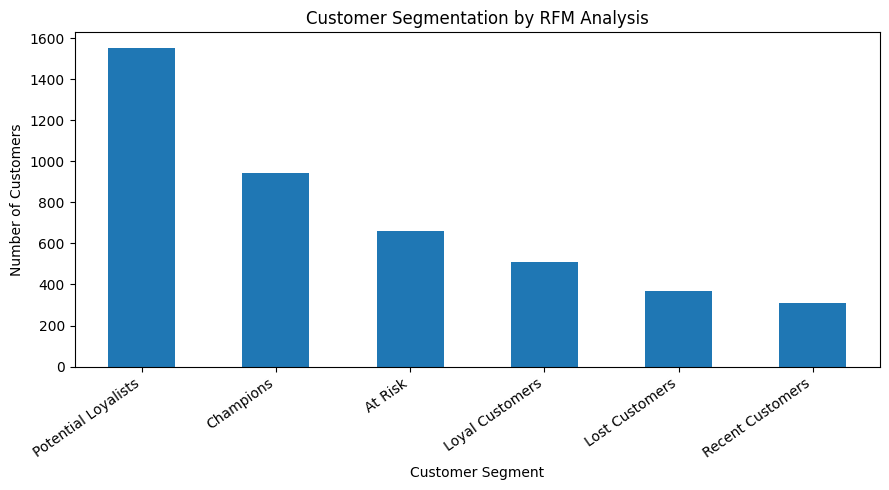

In [46]:

import matplotlib.pyplot as plt

segment_counts = rfm['Segment'].value_counts()

plt.figure(figsize=(9, 5))
segment_counts.plot(kind='bar')
plt.title('Customer Segmentation by RFM Analysis')
plt.xlabel('Customer Segment')
plt.ylabel('Number of Customers')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()


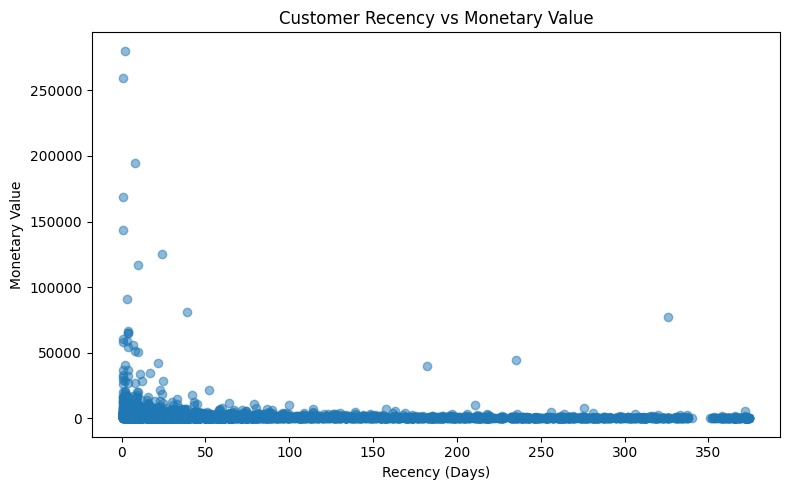

In [47]:
plt.figure(figsize=(8, 5))
plt.scatter(rfm['Recency'], rfm['Monetary'], alpha=0.5)
plt.title('Customer Recency vs Monetary Value')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')
plt.tight_layout()
plt.show()

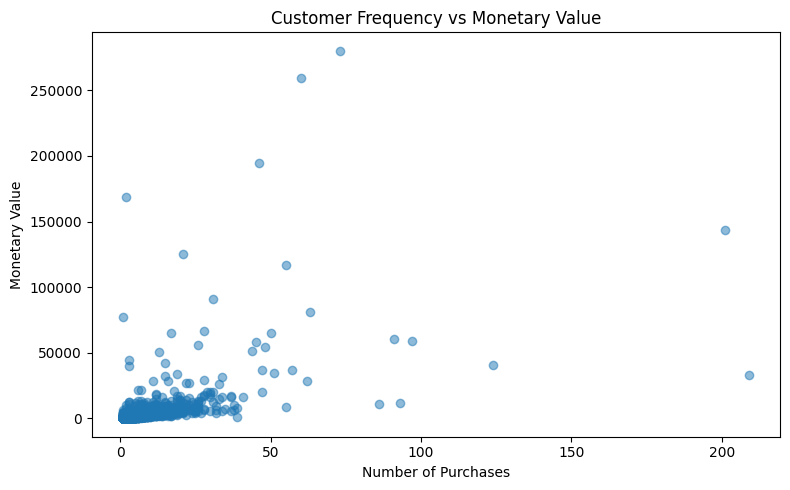

In [48]:
plt.figure(figsize=(8, 5))
plt.scatter(rfm['Frequency'], rfm['Monetary'], alpha=0.5)
plt.title('Customer Frequency vs Monetary Value')
plt.xlabel('Number of Purchases')
plt.ylabel('Monetary Value')
plt.tight_layout()
plt.show()

In [49]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

rfm_features = rfm[['Recency', 'Frequency', 'Monetary']].copy()

rfm_features['Recency'] = rfm_features['Recency'].apply(lambda x: __import__('numpy').log1p(x))
rfm_features['Frequency'] = rfm_features['Frequency'].apply(lambda x: __import__('numpy').log1p(x))
rfm_features['Monetary'] = rfm_features['Monetary'].apply(lambda x: __import__('numpy').log1p(x))

scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm_features)

kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
rfm['Cluster'] = kmeans.fit_predict(rfm_scaled)

print("K-Means clustering completed successfully.")
print("\nCustomer counts by cluster:")
display(
    rfm['Cluster']
    .value_counts()
    .sort_index()
    .rename_axis('Cluster')
    .reset_index(name='Customer Count')
)


K-Means clustering completed successfully.

Customer counts by cluster:


,Cluster,Customer Count
0,0,713
1,1,1622
2,2,837
3,3,1166


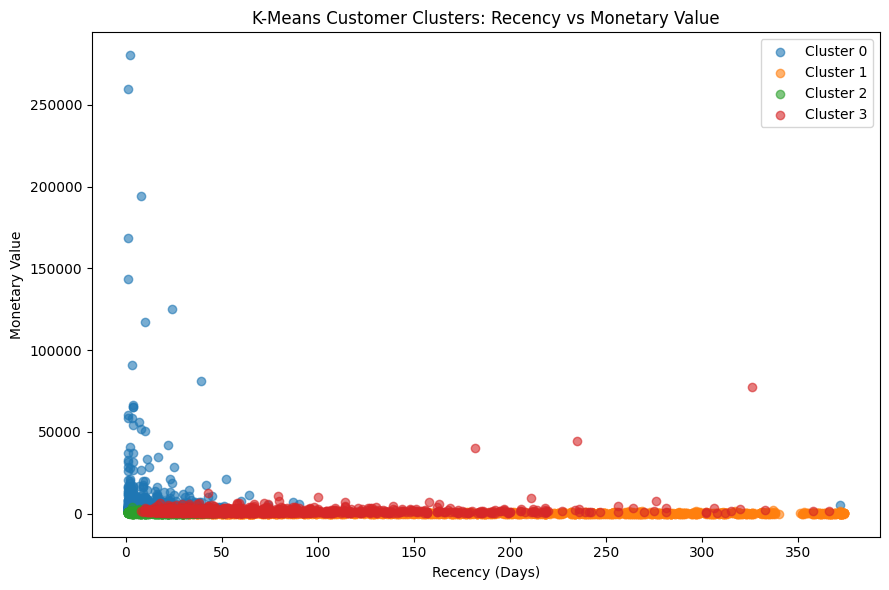

In [50]:
plt.figure(figsize=(9, 6))

for cluster_id in sorted(rfm['Cluster'].unique()):
    cluster_data = rfm[rfm['Cluster'] == cluster_id]

    plt.scatter(
        cluster_data['Recency'],
        cluster_data['Monetary'],
        label=f'Cluster {cluster_id}',
        alpha=0.6
    )

plt.title('K-Means Customer Clusters: Recency vs Monetary Value')
plt.xlabel('Recency (Days)')
plt.ylabel('Monetary Value')
plt.legend()
plt.tight_layout()
plt.show()


In [51]:
cluster_summary = rfm.groupby('Cluster').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).reset_index().round(2)

display(cluster_summary)


,Cluster,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue
0,0,713,12.17,13.75,8088.02,5766757.07
1,1,1622,181.51,1.32,341.00,553099.77
2,2,837,17.70,2.19,557.32,466479.03
3,3,1166,71.64,4.08,1801.78,2100873.02


In [52]:
cluster_names = {
    0: 'High-Value Loyal Customers',
    1: 'Inactive / At-Risk Customers',
    2: 'Recent / Newer Customers',
    3: 'Regular Customers'
}

rfm['KMeans_Segment'] = rfm['Cluster'].map(cluster_names)

display(
    rfm[
        ['CustomerID', 'Recency', 'Frequency', 'Monetary',
         'RFM_Score', 'Segment', 'Cluster', 'KMeans_Segment']
    ].head(10)
)

named_cluster_summary = rfm.groupby(
    ['Cluster', 'KMeans_Segment']
).agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).reset_index().round(2)

display(named_cluster_summary)


,CustomerID,Recency,Frequency,Monetary,RFM_Score,Segment,Cluster,KMeans_Segment
0,12346.0,326,1,77183.60,115,Lost Customers,3,Regular Customers
1,12347.0,2,7,4310.00,555,Champions,0,High-Value Loyal Customers
2,12348.0,75,4,1797.24,244,At Risk,3,Regular Customers
3,12349.0,19,1,1757.55,414,Recent Customers,2,Recent / Newer Customers
4,12350.0,310,1,334.40,112,Lost Customers,1,Inactive / At-Risk Customers
5,12352.0,36,8,2506.04,355,Loyal Customers,3,Regular Customers
6,12353.0,204,1,89.00,111,Lost Customers,1,Inactive / At-Risk Customers
7,12354.0,232,1,1079.40,114,Lost Customers,1,Inactive / At-Risk Customers
8,12355.0,214,1,459.40,112,Lost Customers,1,Inactive / At-Risk Customers
9,12356.0,23,3,2811.43,435,Potential Loyalists,3,Regular Customers


,Cluster,KMeans_Segment,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue
0,0,High-Value Loyal Customers,713,12.17,13.75,8088.02,5766757.07
1,1,Inactive / At-Risk Customers,1622,181.51,1.32,341.00,553099.77
2,2,Recent / Newer Customers,837,17.70,2.19,557.32,466479.03
3,3,Regular Customers,1166,71.64,4.08,1801.78,2100873.02


In [53]:
segment_summary = rfm.groupby('Segment').agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).reset_index().round(2)

named_cluster_summary = rfm.groupby(
    ['Cluster', 'KMeans_Segment']
).agg(
    Customer_Count=('CustomerID', 'count'),
    Average_Recency=('Recency', 'mean'),
    Average_Frequency=('Frequency', 'mean'),
    Average_Monetary=('Monetary', 'mean'),
    Total_Revenue=('Monetary', 'sum')
).reset_index().round(2)

with pd.ExcelWriter(
    'Project 3.xlsx',
    engine='openpyxl'
) as writer:

    rfm.to_excel(
        writer,
        sheet_name='RFM Customer Data',
        index=False
    )

    segment_summary.to_excel(
        writer,
        sheet_name='Segment Summary',
        index=False
    )

    named_cluster_summary.to_excel(
        writer,
        sheet_name='KMeans Cluster Summary',
        index=False
    )

print("Excel workbook created successfully!")
print("File: Project 3.xlsx")

print("\nRFM Segment Summary:")
display(segment_summary)

print("\nK-Means Cluster Summary:")
display(named_cluster_summary)


Excel workbook created successfully!
File: Project 3.xlsx

RFM Segment Summary:


,Segment,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue
0,At Risk,661,150.64,3.41,1246.46,823912.44
1,Champions,942,12.50,11.20,6091.24,5737952.12
2,Lost Customers,366,278.14,1.00,544.00,199104.86
3,Loyal Customers,508,37.21,5.12,1826.03,927623.75
4,Potential Loyalists,1551,105.58,1.53,681.09,1056376.28
5,Recent Customers,310,18.10,1.25,458.84,142239.44



K-Means Cluster Summary:


,Cluster,KMeans_Segment,Customer_Count,Average_Recency,Average_Frequency,Average_Monetary,Total_Revenue
0,0,High-Value Loyal Customers,713,12.17,13.75,8088.02,5766757.07
1,1,Inactive / At-Risk Customers,1622,181.51,1.32,341.00,553099.77
2,2,Recent / Newer Customers,837,17.70,2.19,557.32,466479.03
3,3,Regular Customers,1166,71.64,4.08,1801.78,2100873.02
